In [ ]:
import os
from google.colab import userdata

try:
    # Retrieve the token from Colab Secrets
    HF_TOKEN = userdata.get('HF_TOKEN')

    # Set it as an environment variable
    os.environ["HF_TOKEN"] = HF_TOKEN
    print("Successfully set HF_TOKEN environment variable!")
except Exception as e:
    print("Error retrieving HF_TOKEN. Please ensure you have added 'HF_TOKEN' to your Colab Secrets (the 🔑 icon on the left panel).")

Successfully set HF_TOKEN environment variable!


PyGPT finetuning

In [24]:
!pip install -q datasets transformers tqdm matplotlib

import os
import math
import random
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from dataclasses import dataclass
from datasets import load_dataset
from transformers import AutoTokenizer
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained("bigcode/starcoder")

if tokenizer.eos_token_id is None:
    raise ValueError("StarCoder tokenizer has no EOS token.")

# Reuse EOS as padding. Padding labels will be -100.
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Vocabulary size:", len(tokenizer))
print("EOS token ID:", tokenizer.eos_token_id)
print("Padding token ID:", tokenizer.pad_token_id)

# Load dataset
print("\nLoading Python instruction dataset...")

alpaca_ds = load_dataset(
    "iamtarun/python_code_instructions_18k_alpaca",
    split="train",
)

required_columns = {"instruction", "output"}
missing_columns = required_columns - set(alpaca_ds.column_names)

if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {missing_columns}. "
        f"Available columns: {alpaca_ds.column_names}"
    )

# Select up to 5,000 examples
num_samples = min(5000, len(alpaca_ds))
alpaca_ds = alpaca_ds.select(range(num_samples))

print("Selected examples:", len(alpaca_ds))
print("Dataset columns:", alpaca_ds.column_names)

print("\nExample instruction:")
print(alpaca_ds[0]["instruction"])

print("\nExample output:")
print(str(alpaca_ds[0]["output"])[:1000])

Device: cuda
GPU: Tesla T4
Vocabulary size: 49152
EOS token ID: 0
Padding token ID: 0

Loading Python instruction dataset...
Selected examples: 5000
Dataset columns: ['instruction', 'input', 'output', 'prompt']

Example instruction:
Create a function to calculate the sum of a sequence of integers.

Example output:
# Python code
def sum_sequence(sequence):
  sum = 0
  for num in sequence:
    sum += num
  return sum


In [25]:
import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

from dataclasses import dataclass


class LayerNorm(nn.Module):
    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = (
            nn.Parameter(torch.zeros(ndim)) if bias else None
        )

    def forward(self, x):
        return F.layer_norm(
            x,
            self.weight.shape,
            self.weight,
            self.bias,
            1e-5,
        )


class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len=2048):
        super().__init__()

        inv_freq = 1.0 / (
            10000 ** (
                torch.arange(0, dim, 2).float() / dim
            )
        )

        self.register_buffer("inv_freq", inv_freq)

    def forward(self, seq_len, device):
        t = torch.arange(
            seq_len, device=device
        ).to(dtype=self.inv_freq.dtype)

        freqs = torch.einsum("i,j->ij", t, self.inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)

        return emb.cos(), emb.sin()


def apply_rotary_pos_emb(q, k, cos, sin):
    rot_dim = q.shape[-1]

    cos = cos[..., :rot_dim].to(dtype=q.dtype)
    sin = sin[..., :rot_dim].to(dtype=q.dtype)

    q1, q2 = q[..., :rot_dim // 2], q[..., rot_dim // 2:]
    k1, k2 = k[..., :rot_dim // 2], k[..., rot_dim // 2:]

    q_rot = torch.cat((-q2, q1), dim=-1)
    k_rot = torch.cat((-k2, k1), dim=-1)

    q = q * cos + q_rot * sin
    k = k * cos + k_rot * sin

    return q, k


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.c_attn = nn.Linear(
            config.n_embd,
            3 * config.n_embd,
            bias=config.bias,
        )

        self.c_proj = nn.Linear(
            config.n_embd,
            config.n_embd,
            bias=config.bias,
        )

        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head

        self.rotary_emb = RotaryEmbedding(self.head_dim)

        self.flash = hasattr(
            F, "scaled_dot_product_attention"
        )

        if not self.flash:
            self.register_buffer(
                "bias",
                torch.tril(
                    torch.ones(
                        config.block_size,
                        config.block_size,
                    )
                ).view(
                    1, 1,
                    config.block_size,
                    config.block_size,
                ),
            )

    def forward(self, x):
        B, T, C = x.size()

        q, k, v = self.c_attn(x).split(
            self.n_embd, dim=2
        )

        q = q.view(
            B, T, self.n_head, self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B, T, self.n_head, self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B, T, self.n_head, self.head_dim
        ).transpose(1, 2)

        cos, sin = self.rotary_emb(T, x.device)

        cos = cos[None, None, :, :]
        sin = sin[None, None, :, :]

        q, k = apply_rotary_pos_emb(q, k, cos, sin)

        if self.flash:
            y = F.scaled_dot_product_attention(
                q, k, v, is_causal=True
            )
        else:
            att = (q @ k.transpose(-2, -1)) * (
                1.0 / math.sqrt(k.size(-1))
            )

            att = att.masked_fill(
                self.bias[:, :, :T, :T] == 0,
                float("-inf"),
            )

            att = F.softmax(att, dim=-1)
            y = att @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)

        return self.c_proj(y)


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.c_fc = nn.Linear(
            config.n_embd,
            4 * config.n_embd,
            bias=config.bias,
        )

        self.c_proj = nn.Linear(
            4 * config.n_embd,
            config.n_embd,
            bias=config.bias,
        )

    def forward(self, x):
        return self.c_proj(F.gelu(self.c_fc(x)))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.ln1 = LayerNorm(config.n_embd, config.bias)
        self.attn = CausalSelfAttention(config)

        self.ln2 = LayerNorm(config.n_embd, config.bias)
        self.mlp = MLP(config)

    def forward(self, x):
        # Preserve the residual-block computation used in
        # the provided fine-tuning implementation.
        return (
            x
            + self.attn(self.ln1(x))
            + self.mlp(self.ln2(x))
        )


@dataclass
class GPTConfig:
    block_size: int = 512
    vocab_size: int = 49152
    n_layer: int = 8
    n_head: int = 8
    n_embd: int = 512
    dropout: float = 0.1
    bias: bool = False


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.config = config

        self.transformer = nn.ModuleDict({
            "wte": nn.Embedding(
                config.vocab_size, config.n_embd
            ),
            "drop": nn.Dropout(config.dropout),
            "h": nn.ModuleList([
                Block(config)
                for _ in range(config.n_layer)
            ]),
            "ln_f": LayerNorm(
                config.n_embd, config.bias
            ),
        })

        self.lm_head = nn.Linear(
            config.n_embd,
            config.vocab_size,
            bias=False,
        )

        # Preserve tied input/output embeddings.
        self.transformer.wte.weight = self.lm_head.weight

    def forward(self, idx, targets=None):
        B, T = idx.size()

        if T > self.config.block_size:
            raise ValueError(
                f"Input length {T} exceeds block size "
                f"{self.config.block_size}"
            )

        x = self.transformer.drop(
            self.transformer.wte(idx)
        )

        for block in self.transformer.h:
            x = block(x)

        logits = self.lm_head(
            self.transformer.ln_f(x)
        )

        loss = None

        if targets is not None:
            # Correct next-token prediction alignment.
            shift_logits = logits[:, :-1, :].contiguous()
            shift_labels = targets[:, 1:].contiguous()

            if not (shift_labels != -100).any():
                raise ValueError(
                    "Batch contains no valid target tokens."
                )

            loss = F.cross_entropy(
                shift_logits.float().view(
                    -1, shift_logits.size(-1)
                ),
                shift_labels.reshape(-1),
                ignore_index=-100,
            )

        return logits, loss


# Create architecture
config = GPTConfig(
    block_size=512,
    vocab_size=len(tokenizer),
    n_layer=8,
    n_head=8,
    n_embd=512,
    dropout=0.1,
    bias=False,
)

model = GPT(config)

# Load the pretrained checkpoint.
weights_path = "best_code_model.pt"

if not os.path.exists(weights_path):
    raise FileNotFoundError(
        f"Pretrained checkpoint not found: {weights_path}. "
        "Upload or copy best_code_model.pt into this runtime."
    )

checkpoint = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True,
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

# Do not silently accept a partially loaded pretrained model.
model.load_state_dict(state_dict, strict=True)

model = model.to(device)

print("Pretrained checkpoint loaded successfully.")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Model device:", next(model.parameters()).device)

Pretrained checkpoint loaded successfully.
Parameters: 50,340,352
Model device: cuda:0


In [26]:
MAX_LEN = 512
MAX_PROMPT_TOKENS = 384
MAX_RESPONSE_TOKENS = 128


def format_and_mask(example):
    instruction = str(
        example.get("instruction", "") or ""
    ).strip()

    output = str(
        example.get("output", "") or ""
    ).strip()

    extra_input = str(
        example.get("input", "") or ""
    ).strip()

    if not instruction or not output:
        return {"input_ids": [], "labels": []}

    prompt = f"### Instruction:\n{instruction}\n"

    if extra_input:
        prompt += f"\n### Input:\n{extra_input}\n"

    prompt += "\n### Code:\n"

    prompt_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False,
    )

    response_ids = tokenizer.encode(
        output,
        add_special_tokens=False,
    )

    if not response_ids:
        return {"input_ids": [], "labels": []}

    # Preserve the end of long prompts, including the code marker.
    prompt_ids = prompt_ids[-MAX_PROMPT_TOKENS:]

    # Keep EOS at the end, even when the response is truncated.
    if tokenizer.eos_token_id is not None:
        response_ids = (
            response_ids[:MAX_RESPONSE_TOKENS - 1]
            + [tokenizer.eos_token_id]
        )
    else:
        response_ids = response_ids[:MAX_RESPONSE_TOKENS]

    # Guarantee that the complete sequence fits.
    available = MAX_LEN - len(prompt_ids)
    response_ids = response_ids[:available]

    if not prompt_ids or not response_ids:
        return {"input_ids": [], "labels": []}

    input_ids = prompt_ids + response_ids

    # Prompt tokens are inputs, but not supervised targets.
    labels = (
        [-100] * len(prompt_ids)
        + response_ids.copy()
    )

    assert len(input_ids) == len(labels)
    assert len(input_ids) <= MAX_LEN
    assert all(
        x == -100 for x in labels[:len(prompt_ids)]
    )
    assert all(
        x != -100 for x in labels[len(prompt_ids):]
    )

    return {
        "input_ids": input_ids,
        "labels": labels,
    }


print("Tokenizing examples...")

tokenized_alpaca = alpaca_ds.map(
    format_and_mask,
    remove_columns=alpaca_ds.column_names,
    desc="Formatting and tokenizing",
)

tokenized_alpaca = tokenized_alpaca.filter(
    lambda row: (
        len(row["input_ids"]) >= 2
        and len(row["input_ids"]) == len(row["labels"])
        and any(x != -100 for x in row["labels"][1:])
    ),
    desc="Removing invalid examples",
)

if len(tokenized_alpaca) < 2:
    raise ValueError(
        "Too few valid examples remain after preprocessing."
    )

# Reserve held-out data for validation.
splits = tokenized_alpaca.train_test_split(
    test_size=0.1,
    seed=SEED,
)

train_ds = splits["train"]
val_ds = splits["test"]

print("Training examples:", len(train_ds))
print("Validation examples:", len(val_ds))


def collate_sft(batch):
    batch_size = len(batch)
    max_len = max(len(row["input_ids"]) for row in batch)

    input_ids = torch.full(
        (batch_size, max_len),
        tokenizer.pad_token_id,
        dtype=torch.long,
    )

    labels = torch.full(
        (batch_size, max_len),
        -100,
        dtype=torch.long,
    )

    for i, row in enumerate(batch):
        n = len(row["input_ids"])

        input_ids[i, :n] = torch.tensor(
            row["input_ids"], dtype=torch.long
        )

        labels[i, :n] = torch.tensor(
            row["labels"], dtype=torch.long
        )

    return {
        "input_ids": input_ids,
        "labels": labels,
    }


BATCH_SIZE = 4

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_sft,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_sft,
    pin_memory=(device.type == "cuda"),
)

# Inspect one example before training.
sample = train_ds[0]
sample_ids = sample["input_ids"]
sample_labels = sample["labels"]

first_target = next(
    i for i, token_id in enumerate(sample_labels)
    if token_id != -100
)

print("\n--- MASKING AUDIT ---")
print("Prompt:")
print(tokenizer.decode(sample_ids[:first_target]))

print("\nResponse target:")
print(tokenizer.decode(sample_ids[first_target:]))

print("\nPrompt length:", first_target)
print("Supervised tokens:", sum(
    token_id != -100 for token_id in sample_labels
))

assert all(
    token_id == -100
    for token_id in sample_labels[:first_target]
)

assert any(
    token_id != -100
    for token_id in sample_labels[1:]
)

print("\nDataset preparation passed.")

Tokenizing examples...


Formatting and tokenizing:   0%|          | 0/5000 [00:00<?, ? examples/s]

Removing invalid examples:   0%|          | 0/5000 [00:00<?, ? examples/s]

Training examples: 4500
Validation examples: 500

--- MASKING AUDIT ---
Prompt:
### Instruction:
This code contains a set of tasks to clean, build, and deploy a Python package called Marvin. It also includes tasks to update the default version and module files, update the git package, and set up the package at Utah. To use these tasks, import the `Collection` and `task` functions from the `invoke` module and create a new `Collection` object. Then, add the desired tasks to the collection using the `task` decorator. Finally, run the tasks using the `run` method of the `Context` object.

### Code:


Response target:
# !usr/bin/env python2
# -*- coding: utf-8 -*-
#
# Licensed under a 3-clause BSD license.
#
# @Author: Brian Cherinka
# @Date:   2017-06-10 16:46:40
# @Last modified by: José Sánchez-Gallego (gallegoj@uw.edu)
# @Last modified time: 2018-11-14 19:37:22

<|endoftext|>

Prompt length: 123
Supervised tokens: 128

Dataset preparation passed.


Starting corrected supervised fine-tuning...


/tmp/ipykernel_781/1955528558.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(


Training:   0%|          | 0/1125 [00:00<?, ?it/s]

/tmp/ipykernel_781/1955528558.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Validation:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1/2 | Train loss: 3.1639 | Validation loss: 2.8189
Saved new best validation checkpoint.


Training:   0%|          | 0/1125 [00:00<?, ?it/s]

Validation:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2/2 | Train loss: 2.6550 | Validation loss: 2.5881
Saved new best validation checkpoint.

Training finished.
Best epoch: 2
Best validation loss: 2.5881
Checkpoint: fine_tuned_code_model.pt


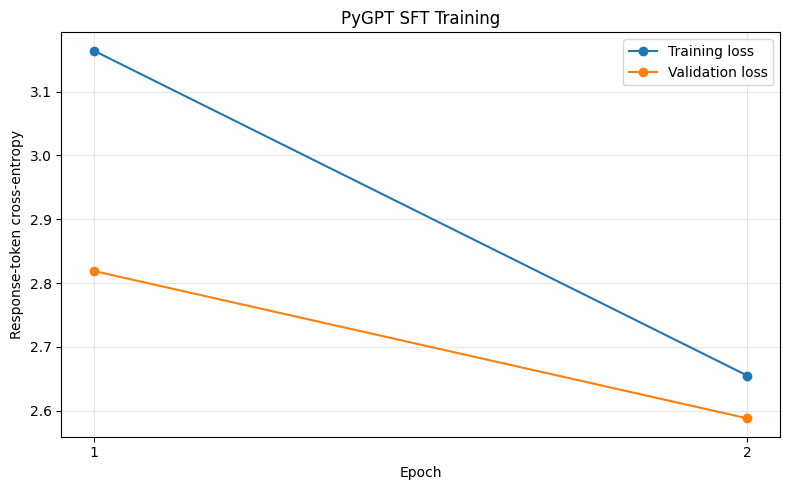

Loss graph saved to sft_loss.png


In [27]:
import copy
import matplotlib.pyplot as plt

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
EPOCHS = 2
MAX_GRAD_NORM = 1.0

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

# FP16 mixed precision for CUDA/T4; FP32 on CPU.
use_amp = device.type == "cuda"

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)

train_history = []
val_history = []

best_val_loss = float("inf")
best_epoch = None

CHECKPOINT_PATH = "fine_tuned_code_model.pt"


def run_epoch(loader, training):
    model.train(training)

    total_loss_times_tokens = 0.0
    total_target_tokens = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False,
    )

    for batch in progress:
        inputs = batch["input_ids"].to(
            device, non_blocking=True
        )

        targets = batch["labels"].to(
            device, non_blocking=True
        )

        # These labels correspond to predictions after shifting.
        target_count = int(
            (targets[:, 1:] != -100).sum().item()
        )

        if target_count == 0:
            continue

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.cuda.amp.autocast(
                enabled=use_amp,
                dtype=torch.float16,
            ):
                _, loss = model(inputs, targets=targets)

            if loss is None or not torch.isfinite(loss):
                raise RuntimeError(
                    f"Invalid loss encountered: {loss}"
                )

            if training:
                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    MAX_GRAD_NORM,
                )

                scaler.step(optimizer)
                scaler.update()

        total_loss_times_tokens += (
            loss.detach().item() * target_count
        )
        total_target_tokens += target_count

        progress.set_postfix(
            loss=f"{loss.detach().item():.4f}",
            target_tokens=target_count,
        )

    if total_target_tokens == 0:
        raise RuntimeError(
            "No valid response tokens were evaluated."
        )

    return (
        total_loss_times_tokens / total_target_tokens
    )


print("Starting corrected supervised fine-tuning...")

for epoch in range(EPOCHS):
    train_loss = run_epoch(
        train_loader, training=True
    )

    val_loss = run_epoch(
        val_loader, training=False
    )

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": best_epoch,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "config": {
                    "block_size": config.block_size,
                    "vocab_size": config.vocab_size,
                    "n_layer": config.n_layer,
                    "n_head": config.n_head,
                    "n_embd": config.n_embd,
                    "dropout": config.dropout,
                    "bias": config.bias,
                },
                "tokenizer_name": "bigcode/starcoder",
            },
            CHECKPOINT_PATH,
        )

        print("Saved new best validation checkpoint.")

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", CHECKPOINT_PATH)

# Save a loss graph for your project README.
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(train_history) + 1),
    train_history,
    marker="o",
    label="Training loss",
)
plt.plot(
    range(1, len(val_history) + 1),
    val_history,
    marker="o",
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("Response-token cross-entropy")
plt.title("PyGPT SFT Training")
plt.xticks(range(1, len(train_history) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("sft_loss.png", dpi=200)
plt.show()

print("Loss graph saved to sft_loss.png")

In [38]:
import torch
import torch.nn.functional as F

CHECKPOINT_PATH = "fine_tuned_code_model.pt"

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        "SFT checkpoint not found. Run Cell 4 first."
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)

# Reuse the same architecture and tokenizer.
inference_model = GPT(config)

inference_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

inference_model = inference_model.to(device)
inference_model.eval()

print("Loaded SFT checkpoint.")
print("Best epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])


@torch.no_grad()
def generate_code(
    model,
    instruction,
    extra_input="",
    max_new_tokens=160,
    temperature=0.0,
    top_k=40,
):
    model.eval()

    prompt = f"### Instruction:\n{instruction.strip()}\n"

    if extra_input.strip():
        prompt += f"\n### Input:\n{extra_input.strip()}\n"

    prompt += "\n### Code:\n"

    input_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False,
    )

    if len(input_ids) > model.config.block_size:
        input_ids = input_ids[-model.config.block_size:]

    idx = torch.tensor(
        [input_ids],
        dtype=torch.long,
        device=device,
    )

    prompt_length = idx.shape[1]

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.config.block_size:]

        logits, _ = model(idx_cond)
        next_logits = logits[:, -1, :].float()

        # Greedy decoding for debugging.
        if temperature <= 0:
            next_token = torch.argmax(
                next_logits,
                dim=-1,
                keepdim=True,
            )

        else:
            next_logits = next_logits / temperature

            # Do not generate padding if it is a separate token.
            # If padding equals EOS, EOS must remain available.
            if (
                tokenizer.pad_token_id is not None
                and tokenizer.pad_token_id
                != tokenizer.eos_token_id
            ):
                next_logits[:, tokenizer.pad_token_id] = (
                    float("-inf")
                )

            if top_k is not None:
                k = min(top_k, next_logits.size(-1))

                values, _ = torch.topk(next_logits, k)
                threshold = values[:, [-1]]

                next_logits = next_logits.masked_fill(
                    next_logits < threshold,
                    float("-inf"),
                )

            probs = F.softmax(next_logits, dim=-1)

            if not torch.isfinite(probs).all():
                raise RuntimeError(
                    "Invalid probabilities during generation."
                )

            next_token = torch.multinomial(
                probs, num_samples=1
            )

        idx = torch.cat([idx, next_token], dim=1)

        if (
            tokenizer.eos_token_id is not None
            and next_token.item() == tokenizer.eos_token_id
        ):
            break

    generated_ids = idx[0, prompt_length:].tolist()

    return tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
    )


# First test: deterministic greedy generation.
test_instruction = (
    "Write a Python function to check if a number is prime."
)

generated_code = generate_code(
    inference_model,
    test_instruction,
    max_new_tokens=160,
    temperature=0.0,
)

print("\n--- GENERATED RESPONSE ---\n")
print(generated_code)

Loaded SFT checkpoint.
Best epoch: 2
Validation loss: 2.5881193405215654

--- GENERATED RESPONSE ---

def is_prime(n):
    if n == 0:
        return False
    else:
        return False


In [57]:
sampled_code = generate_code(
    inference_model,
    "Write a Python function to check if a number is even or not.",
    max_new_tokens=160,
    temperature=0.7,
    top_k=40,
)

print(sampled_code)

def is_a_a(x):
    return True
 
 def is_a_a(x):
    return x[x - 1]:
 return None
